<p align="center">🩺 <strong>Projet Traitement des données</strong></p>


       # Prédiction des absences aux rendez-vous médicaux

* Ce projet utilise le dataset **Medical Appointment No Shows** pour prédire si un patient va honorer ou non son rendez-vous médical.






**📦Importation des librairies**


In [ ]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score
import pickle



**📂 Chargement du dataset**

In [ ]:
data = pd.read_csv('/content/patient.csv')

**📊Exploration du dataset**

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 110527 entries, 0 to 110526
Data columns (total 14 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   PatientId       110527 non-null  float64
 1   AppointmentID   110527 non-null  int64  
 2   Gender          110527 non-null  object 
 3   ScheduledDay    110527 non-null  object 
 4   AppointmentDay  110527 non-null  object 
 5   Age             110527 non-null  int64  
 6   Neighbourhood   110527 non-null  object 
 7   Scholarship     110527 non-null  int64  
 8   Hipertension    110527 non-null  int64  
 9   Diabetes        110527 non-null  int64  
 10  Alcoholism      110527 non-null  int64  
 11  Handcap         110527 non-null  int64  
 12  SMS_received    110527 non-null  int64  
 13  No-show         110527 non-null  object 
dtypes: float64(1), int64(8), object(5)
memory usage: 11.8+ MB


In [ ]:
data.head()

,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
0,2.987250e+13,5642903,F,2016-04-29T18:38:08Z,2016-04-29T00:00:00Z,62,JARDIM DA PENHA,0,1,0,0,0,0,No
1,5.589978e+14,5642503,M,2016-04-29T16:08:27Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,0,0,0,0,0,No
2,4.262962e+12,5642549,F,2016-04-29T16:19:04Z,2016-04-29T00:00:00Z,62,MATA DA PRAIA,0,0,0,0,0,0,No
3,8.679512e+11,5642828,F,2016-04-29T17:29:31Z,2016-04-29T00:00:00Z,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No
4,8.841186e+12,5642494,F,2016-04-29T16:07:23Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,1,1,0,0,0,No


In [ ]:
data.tail()

,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
110522,2.572134e+12,5651768,F,2016-05-03T09:15:35Z,2016-06-07T00:00:00Z,56,MARIA ORTIZ,0,0,0,0,0,1,No
110523,3.596266e+12,5650093,F,2016-05-03T07:27:33Z,2016-06-07T00:00:00Z,51,MARIA ORTIZ,0,0,0,0,0,1,No
110524,1.557663e+13,5630692,F,2016-04-27T16:03:52Z,2016-06-07T00:00:00Z,21,MARIA ORTIZ,0,0,0,0,0,1,No
110525,9.213493e+13,5630323,F,2016-04-27T15:09:23Z,2016-06-07T00:00:00Z,38,MARIA ORTIZ,0,0,0,0,0,1,No
110526,3.775115e+14,5629448,F,2016-04-27T13:30:56Z,2016-06-07T00:00:00Z,54,MARIA ORTIZ,0,0,0,0,0,1,No


In [ ]:
print(f"lignes: {data.shape[0]}, Colonnes: {data.shape[1]}")

lignes: 110527, Colonnes: 14


In [ ]:
print("\nMissing values:\n", data.isnull().sum())


Missing values:
 PatientId         0
AppointmentID     0
Gender            0
ScheduledDay      0
AppointmentDay    0
Age               0
Neighbourhood     0
Scholarship       0
Hipertension      0
Diabetes          0
Alcoholism        0
Handcap           0
SMS_received      0
No-show           0
dtype: int64


In [ ]:
print(f"Doublons détectés : {data.duplicated().sum()}")

Doublons détectés : 0


In [ ]:
data.describe()

,PatientId,AppointmentID,Age,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received
count,1.105270e+05,1.105270e+05,110527.000000,110527.000000,110527.000000,110527.000000,110527.000000,110527.000000,110527.000000
mean,1.474963e+14,5.675305e+06,37.088874,0.098266,0.197246,0.071865,0.030400,0.022248,0.321026
std,2.560949e+14,7.129575e+04,23.110205,0.297675,0.397921,0.258265,0.171686,0.161543,0.466873
min,3.921784e+04,5.030230e+06,-1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,4.172614e+12,5.640286e+06,18.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,3.173184e+13,5.680573e+06,37.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,9.439172e+13,5.725524e+06,55.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
max,9.999816e+14,5.790484e+06,115.000000,1.000000,1.000000,1.000000,1.000000,4.000000,1.000000


 **🧹 Nettoyage et prétraitement des données**



## Suppression des colonnes inutiles

In [ ]:
data = data.drop(['PatientId', 'AppointmentID'], axis=1)
print(f"lignes: {data.shape[0]}, Colonnes: {data.shape[1]} (après suppression des IDs)")

lignes: 110527, Colonnes: 12 (après suppression des IDs)


In [ ]:
data.head(1)

,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
0,F,2016-04-29T18:38:08Z,2016-04-29T00:00:00Z,62,JARDIM DA PENHA,0,1,0,0,0,0,No


## Vérification des valeurs erronées

In [ ]:
print("Nombre de patients avec un âge < 1 :", data[data['Age'] < 1].shape[0])


Nombre de patients avec un âge < 1 : 3540


## Correction des valeurs aberrantes dans la colonne Age

In [ ]:
median_age = data[data['Age'] >= 1]['Age'].median()
data.loc[data['Age'] < 1, 'Age'] = median_age

##Analyse des outliers dans l'âge avec un boxplot





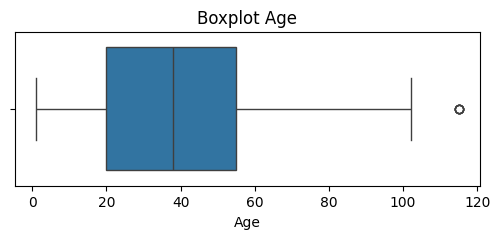

In [ ]:
plt.figure(figsize=(6, 2))
sns.boxplot(x=data['Age'])
plt.title('Boxplot Age')
plt.show()

##Suppression des outliers

In [ ]:
data = data[data['Age'] < 115]

## Gestion de l'âge : création de groupes et encodage

In [ ]:
bins = [0, 60, 150]
labels = ['LessThan60', '60andMore']
data['AgeGroup'] = pd.cut(data['Age'], bins=bins, labels=labels, right=False)

data = pd.get_dummies(data, columns=['AgeGroup'], drop_first=True)

data['AgeGroup_60andMore'] = data['AgeGroup_60andMore'].astype(int)

data.head()


,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show,AgeGroup_60andMore
0,F,2016-04-29T18:38:08Z,2016-04-29T00:00:00Z,62.0,JARDIM DA PENHA,0.0,1.0,0.0,0.0,0.0,0.0,No,1
1,M,2016-04-29T16:08:27Z,2016-04-29T00:00:00Z,56.0,JARDIM DA PENHA,0.0,0.0,0.0,0.0,0.0,0.0,No,0
2,F,2016-04-29T16:19:04Z,2016-04-29T00:00:00Z,62.0,MATA DA PRAIA,0.0,0.0,0.0,0.0,0.0,0.0,No,1
3,F,2016-04-29T17:29:31Z,2016-04-29T00:00:00Z,8.0,PONTAL DE CAMBURI,0.0,0.0,0.0,0.0,0.0,0.0,No,0
4,F,2016-04-29T16:07:23Z,2016-04-29T00:00:00Z,56.0,JARDIM DA PENHA,0.0,1.0,1.0,0.0,0.0,0.0,No,0


In [ ]:
data.drop('Age', axis=1, inplace=True)

In [ ]:
data.describe()

,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,AgeGroup_60andMore
count,21514.000000,21514.000000,21514.000000,21514.000000,21514.000000,21514.000000,21514.000000
mean,0.088082,0.184577,0.062517,0.047039,0.020359,0.307939,0.169564
std,0.283421,0.387963,0.242099,0.211728,0.152313,0.461652,0.375258
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
max,1.000000,1.000000,1.000000,1.000000,3.000000,1.000000,1.000000


In [ ]:
pd.DataFrame(data['Handcap'].unique())

,0
0,0.0
1,1.0
2,2.0
3,3.0


In [ ]:
data.loc[data['Handcap'] > 0, 'Handcap'] = 1
print('Values in Handcap:', data['Handcap'].unique())

Values in Handcap: [0. 1.]


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 21514 entries, 0 to 21513
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Gender              21514 non-null  object 
 1   ScheduledDay        21514 non-null  object 
 2   AppointmentDay      21514 non-null  object 
 3   Neighbourhood       21514 non-null  object 
 4   Scholarship         21514 non-null  float64
 5   Hipertension        21514 non-null  float64
 6   Diabetes            21514 non-null  float64
 7   Alcoholism          21514 non-null  float64
 8   Handcap             21514 non-null  float64
 9   SMS_received        21514 non-null  float64
 10  No-show             21514 non-null  object 
 11  AgeGroup_60andMore  21514 non-null  int64  
dtypes: float64(6), int64(1), object(5)
memory usage: 2.6+ MB


## Analyse de la distribution des genres

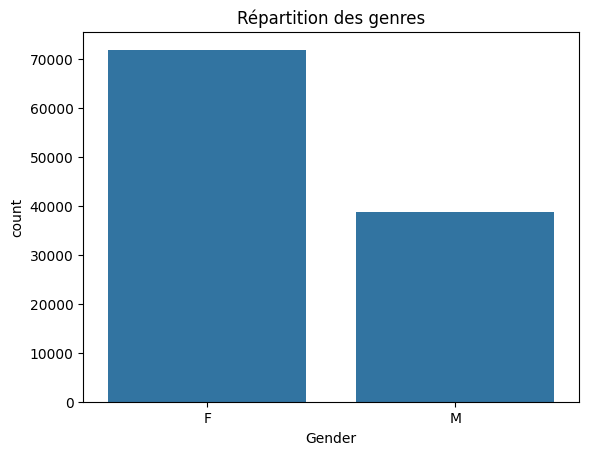

In [ ]:
sns.countplot(x='Gender', data=data)
plt.title('Répartition des genres')
plt.show()


## Encodage des genres (F/M) en 0 et 1

In [ ]:
data['Gender'] = data['Gender'].map({'F': 0, 'M': 1})

In [ ]:
data['ScheduledDay'] = pd.to_datetime(data['ScheduledDay'])
data['AppointmentDay'] = pd.to_datetime(data['AppointmentDay'])
data.head(1)

,Gender,ScheduledDay,AppointmentDay,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show,AgeGroup_60andMore
0,0,2016-04-29 18:38:08+00:00,2016-04-29 00:00:00+00:00,JARDIM DA PENHA,0,1,0,0,0,0,No,1


In [ ]:
data['ScheduledDay'] = data['ScheduledDay'].dt.date
data['AppointmentDay'] = data['AppointmentDay'].dt.date
data.head(1)

,Gender,ScheduledDay,AppointmentDay,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show,AgeGroup_60andMore
0,0,2016-04-29,2016-04-29,JARDIM DA PENHA,0,1,0,0,0,0,No,1


## Création de la variable 'waiting_days'

In [ ]:
data['waiting_days'] = (pd.to_datetime(data['AppointmentDay']) - pd.to_datetime(data['ScheduledDay'])).dt.days

In [ ]:
columns_to_drop = ['ScheduledDay', 'AppointmentDay']
data.drop(columns=columns_to_drop, inplace=True)

In [ ]:
data.head(20)

,Gender,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show,AgeGroup_60andMore,waiting_days
0,0,JARDIM DA PENHA,0,1,0,0,0,0,No,1,0
1,1,JARDIM DA PENHA,0,0,0,0,0,0,No,0,0
2,0,MATA DA PRAIA,0,0,0,0,0,0,No,1,0
3,0,PONTAL DE CAMBURI,0,0,0,0,0,0,No,0,0
4,0,JARDIM DA PENHA,0,1,1,0,0,0,No,0,0
5,0,REPÚBLICA,0,1,0,0,0,0,No,1,2
6,0,GOIABEIRAS,0,0,0,0,0,0,Yes,0,2
7,0,GOIABEIRAS,0,0,0,0,0,0,Yes,0,2
8,0,ANDORINHAS,0,0,0,0,0,0,No,0,0
9,0,CONQUISTA,0,0,0,0,0,0,No,0,2


##Analyse des outliers dans Waiting_days avec un boxplot

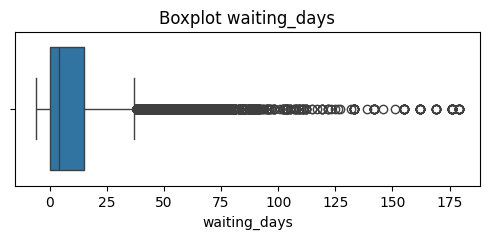

In [ ]:
plt.figure(figsize=(6, 2))
sns.boxplot(x=data['waiting_days'])
plt.title('Boxplot waiting_days')
plt.show()

##Correction des outliers

In [ ]:
col = 'waiting_days'
Q1, Q3 = data[col].quantile([0.25, 0.75])
IQR = Q3 - Q1
lb, ub = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR

before_outliers = ((data[col] < lb) | (data[col] > ub)).sum()

data[col] = data[col].apply(lambda x: lb if x < lb else ub if x > ub else x)

after_outliers = ((data[col] < lb) | (data[col] > ub)).sum()

print(f"✅ {before_outliers} outliers corrigés dans '{col}' — {after_outliers} restants")



✅ 2661 outliers corrigés dans 'waiting_days' — 0 restants


In [ ]:
data['waiting_days'] = data['waiting_days'].astype(int)

In [ ]:
print("Nombre de waiting_days < 0 :", data[data['waiting_days'] < 0].shape[0])

Nombre de waiting_days < 0 : 0


In [ ]:
data = data[data['waiting_days'] >=0]

In [ ]:
data.head()

,Gender,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show,AgeGroup_60andMore,waiting_days
0,0,JARDIM DA PENHA,0.0,1.0,0.0,0.0,0.0,0.0,No,1,0
1,1,JARDIM DA PENHA,0.0,0.0,0.0,0.0,0.0,0.0,No,0,0
2,0,MATA DA PRAIA,0.0,0.0,0.0,0.0,0.0,0.0,No,1,0
3,0,PONTAL DE CAMBURI,0.0,0.0,0.0,0.0,0.0,0.0,No,0,0
4,0,JARDIM DA PENHA,0.0,1.0,1.0,0.0,0.0,0.0,No,0,0


In [ ]:
data = data.drop(columns=['Neighbourhood'])

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 21514 entries, 0 to 21513
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Gender              21514 non-null  int64  
 1   Scholarship         21514 non-null  float64
 2   Hipertension        21514 non-null  float64
 3   Diabetes            21514 non-null  float64
 4   Alcoholism          21514 non-null  float64
 5   Handcap             21514 non-null  float64
 6   SMS_received        21514 non-null  float64
 7   No-show             21514 non-null  object 
 8   AgeGroup_60andMore  21514 non-null  int64  
 9   waiting_days        21514 non-null  int64  
dtypes: float64(6), int64(3), object(1)
memory usage: 2.3+ MB


## Encodage de la colonne " No-show "

In [ ]:
data['No-show'] = data['No-show'].map({'No': 0, 'Yes': 1})

In [ ]:
data_corr = data.corr(numeric_only=True)

## Visualisation de la matrice de corrélation

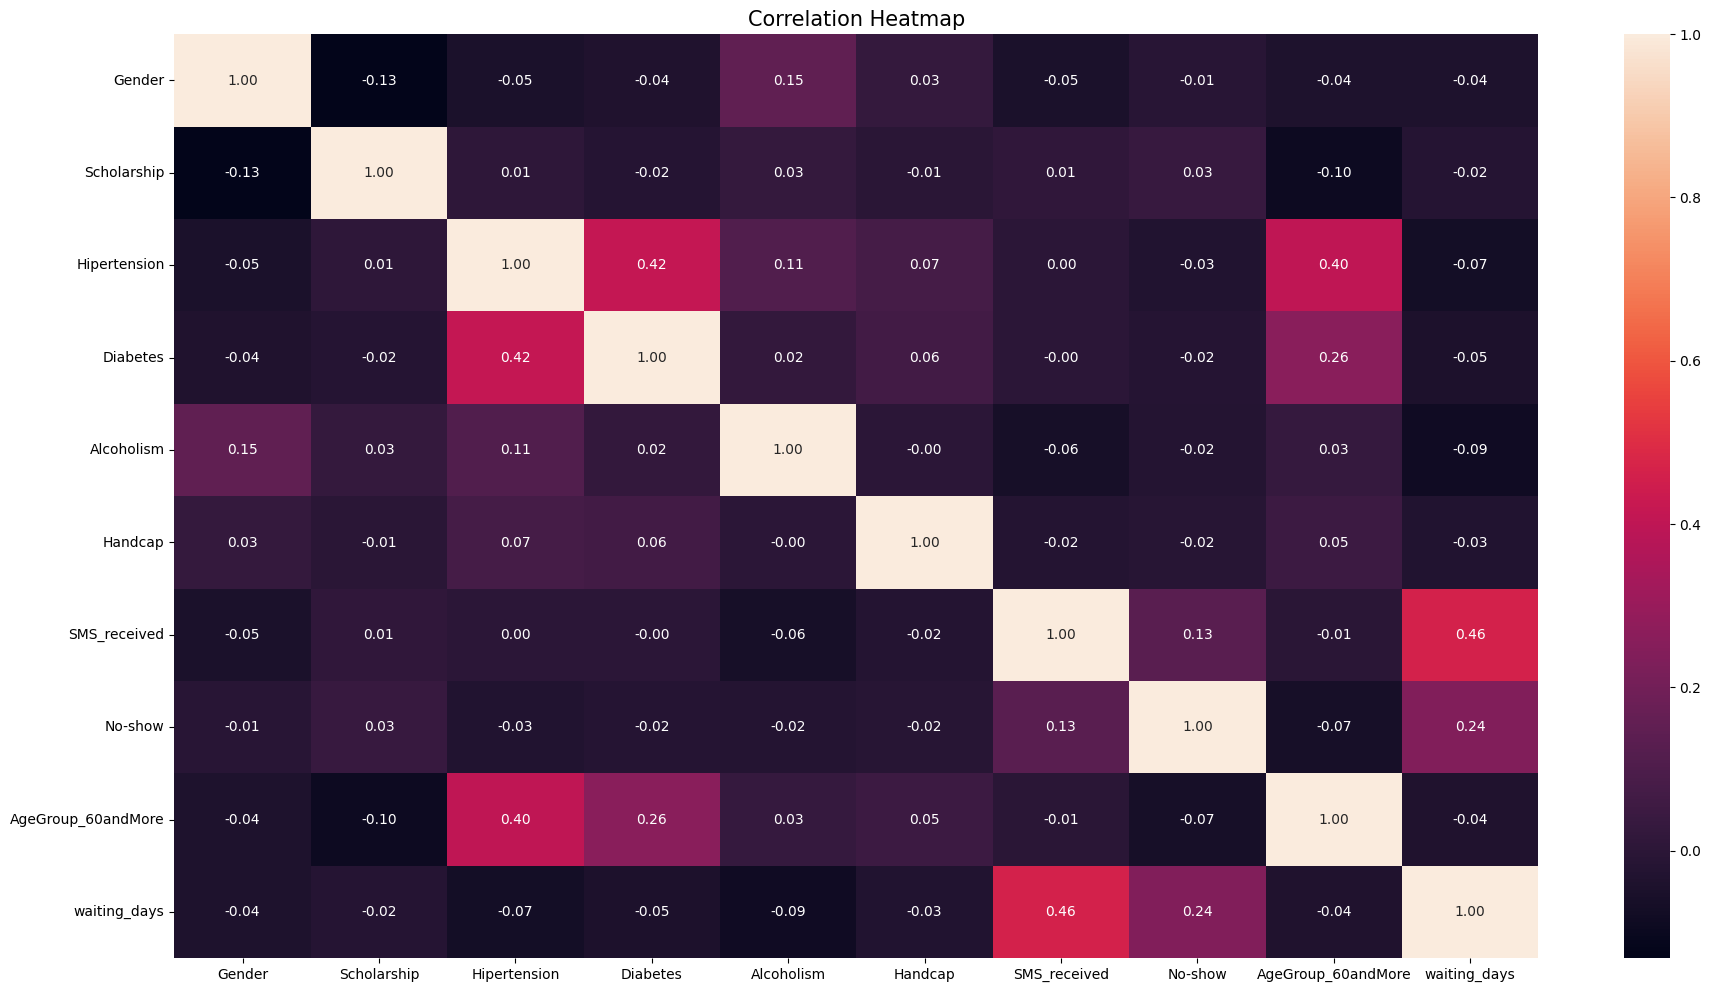

In [ ]:
plt.figure(figsize=(22, 12))
sns.heatmap(data_corr, annot=True, fmt='.2f')
plt.title("Correlation Heatmap", fontsize=15)
plt.show()

In [ ]:
data_log = data.copy()

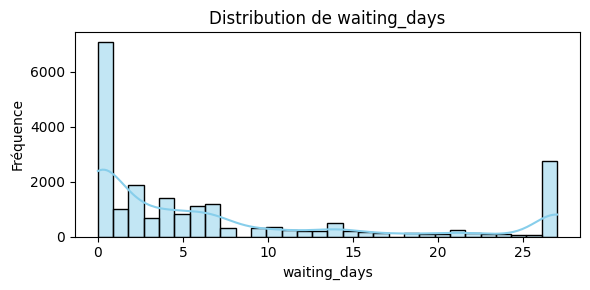

In [ ]:
plt.figure(figsize=(6, 3))
sns.histplot(data['waiting_days'], kde=True, bins=30, color='skyblue')
plt.title('Distribution de waiting_days')
plt.xlabel('waiting_days')
plt.ylabel('Fréquence')
plt.tight_layout()
plt.show()


In [ ]:
data_log['waiting_days'] = np.log1p(data_log['waiting_days'])


In [ ]:
print(f"data lignes: {data.shape[0]},  data_Log lignes: {data_log.shape[0]}")


data lignes: 21514,  data_Log lignes: 21514


# Fonction pour tester plusieurs modèles


In [ ]:
def train_all_classifiers(X_train, X_test, y_train, y_test):
    models = {
        'Logistic Regression': LogisticRegression(max_iter=1000),
        'Support Vector Machine': SVC(),
        'Gradient Boosting': GradientBoostingClassifier(),
        'K-Nearest Neighbors': KNeighborsClassifier()
    }
    results = {}
    for name, model in models.items():
        model.fit(X_train, y_train)
        preds = model.predict(X_test)

        acc = accuracy_score(y_test, preds)
        results[name] = round(acc, 4)
        print(f"📌 {name} - Accuracy: {acc * 100:.2f}% ")
    return results

 # Fonction pour évaluer une version





In [ ]:
def evaluate_version(df, version_name):
    print(f"\n=== Évaluation: {version_name} ===")
    X = df[['Scholarship', 'Hipertension', 'Diabetes', 'Alcoholism',
            'Handcap', 'SMS_received', 'AgeGroup_60andMore', 'waiting_days']]
    y = df['No-show']

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.3, stratify=y, random_state=42,shuffle=True
    )

    return train_all_classifiers(X_train, X_test, y_train, y_test)


# Évaluer les 2 versions

In [ ]:
results_base = evaluate_version(data, "Version de base")
results_log = evaluate_version(data_log, "Log-transform sur waiting_days")

all_results = {
    'Base': results_base,
    'Log-transformed': results_log
}


=== Évaluation: Version de base ===
📌 Logistic Regression - Accuracy: 79.91% 
📌 Support Vector Machine - Accuracy: 79.91% 
📌 Gradient Boosting - Accuracy: 80.00% 
📌 K-Nearest Neighbors - Accuracy: 77.82% 

=== Évaluation: Log-transform sur waiting_days ===
📌 Logistic Regression - Accuracy: 79.92% 
📌 Support Vector Machine - Accuracy: 79.91% 
📌 Gradient Boosting - Accuracy: 80.00% 
📌 K-Nearest Neighbors - Accuracy: 76.28% 


# Choix du meilleur modèle

In [ ]:
best_score = 0
best_model = ""
best_version = ""

for version, models in all_results.items():
    for name, score in models.items():
        if score > best_score:
            best_score = score
            best_model = name
            best_version = version

print(f"\n✅ Meilleur modèle : {best_model} sur {best_version} avec une accuracy de {best_score * 100:.2f}%")



✅ Meilleur modèle : Gradient Boosting sur Base avec une accuracy de 80.00%


 # Entraînement final

In [ ]:
model_map = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Support Vector Machine': SVC(),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'K-Nearest Neighbors': KNeighborsClassifier()
}
df_map = {
    'Base': data,
    'Log-transformed': data_log
}

In [ ]:
# Données finales
df_final = df_map[best_version]
X_final = df_final[['Scholarship', 'Hipertension', 'Diabetes', 'Alcoholism',
                    'Handcap', 'SMS_received', 'AgeGroup_60andMore', 'waiting_days']]
y_final = df_final['No-show']

# Entraînement
final_model = model_map[best_model]
final_model.fit(X_final, y_final)

GradientBoostingClassifier(random_state=42)

**📤 Export du modèle et téléchargement 🔽**

In [ ]:

filename = f"{best_model.replace(' ', '_').lower()}_{best_version.lower()}_noshow_model.pkl"
with open(filename, 'wb') as file:
    pickle.dump(final_model, file)

print(f" Modèle sauvegardé sous : '{filename}'")

 Modèle sauvegardé sous : 'gradient_boosting_base_noshow_model.pkl'


In [ ]:
from google.colab import files
files.download('gradient_boosting_base_noshow_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<p align="center">🚀 <strong>Projet Traitement des données</strong></p> <p align="center">👤 <strong>Nom :</strong> Amri</p> <p align="center">👩‍💻 <strong>Prénom :</strong> Nour</p> <p align="center">🏫 <strong>Classe :</strong> 1DNI 1</p> <p align="center">📅 <strong>Année universitaire :</strong> 2024/2025</p>
